# ClearBank: Análise Financeira de Transações

**Desafio final do módulo de Análise de Dados e Inteligência de Negócios com IA.**

## Instruções de uso deste notebook

1. O arquivo `transacoes.csv` já está na mesma pasta deste notebook. Ele contém
   **20 transações válidas** distribuídas em **4 meses** (2026-01 a 2026-04),
   **5 transações inválidas** (uma para cada regra de validação exigida) e
   **2 transações acima de R$ 10.000,00** (marcadas como suspeitas).
2. Execute as células **em ordem, de cima para baixo**. O notebook segue a
   sequência: leitura → validação → datas → métricas → JSON → relatório.
3. Cada função tem, logo abaixo, uma célula de **teste rápido**: execute-a
   para conferir o comportamento antes de seguir em frente.
4. A **Célula de Execução Principal** (seção 10) chama todas as funções juntas
   e deve ser executada por último, como validação final do projeto.
5. As seções 11 e 12 são **opcionais** (pandas e matplotlib).

**Constante de negócio:** transações com `valor` acima de `LIMITE_SUSPEITO`
(R$ 10.000,00) são sinalizadas como suspeitas no relatório final.


## 1. Importações e Constantes

In [1]:
import csv
import json
from datetime import datetime

# Nome dos arquivos de entrada e saída
ARQUIVO_CSV = "transacoes.csv"
ARQUIVO_JSON = "relatorio.json"

# Qualquer transação com valor acima deste limite é marcada como suspeita
LIMITE_SUSPEITO = 10000.00


## 2. Leitura do arquivo CSV

`ler_transacoes()` usa o módulo `csv` nativo (`csv.DictReader`) para ler o
arquivo e devolver a lista de linhas **brutas** (ainda sem validação), uma
por dicionário. Se o arquivo não existir, o erro `FileNotFoundError` é
capturado e a função devolve uma lista vazia em vez de encerrar o programa.

In [2]:
def ler_transacoes(caminho):
    """Lê o CSV informado e retorna a lista de linhas brutas (dicionários)."""
    linhas = []
    try:
        with open(caminho, mode="r", encoding="utf-8", newline="") as arquivo:
            leitor = csv.DictReader(arquivo)
            for linha in leitor:
                linhas.append(linha)
    except FileNotFoundError:
        print(f"Erro: o arquivo '{caminho}' não foi encontrado.")
        return []
    return linhas


In [3]:
# Teste rápido
linhas_teste = ler_transacoes(ARQUIVO_CSV)
print(f"Linhas lidas: {len(linhas_teste)}")
print("Primeira linha:", linhas_teste[0])

# Teste do caso de arquivo inexistente
print("\nTeste com arquivo inexistente:")
resultado_vazio = ler_transacoes("arquivo_que_nao_existe.csv")
print("Resultado:", resultado_vazio)


Linhas lidas: 25
Primeira linha: {'id': '1', 'data': '2026-01-05', 'cliente_id': 'CLI001', 'tipo': 'credito', 'valor': '3500.00', 'descricao': 'Salário janeiro', 'categoria': 'salario'}

Teste com arquivo inexistente:
Erro: o arquivo 'arquivo_que_nao_existe.csv' não foi encontrado.
Resultado: []


## 3. Funções de validação de campos individuais

Duas funções auxiliares, uma só para `data` e outra só para `valor`, cada
uma protegida com `try/except`, para ficarem fáceis de reutilizar e testar
isoladamente.

In [4]:
def validar_data(data_texto):
    """Converte um texto AAAA-MM-DD em datetime. Retorna None se for inválido."""
    try:
        return datetime.strptime(data_texto.strip(), "%Y-%m-%d")
    except (ValueError, AttributeError):
        return None


def validar_valor(valor_texto):
    """Converte um texto em float positivo. Retorna None se for inválido."""
    try:
        valor = float(valor_texto)
    except (ValueError, TypeError):
        return None
    if valor <= 0:
        return None
    return valor


In [5]:
# Teste rápido
print("Datas:")
print(" '2026-01-05' ->", validar_data("2026-01-05"))
print(" '2026-04-31' ->", validar_data("2026-04-31"))  # dia inválido para abril
print(" '' ->", validar_data(""))

print("\nValores:")
print(" '150.50' ->", validar_valor("150.50"))
print(" 'abc'    ->", validar_valor("abc"))
print(" '-10'    ->", validar_valor("-10"))
print(" '0'      ->", validar_valor("0"))


Datas:
 '2026-01-05' -> 2026-01-05 00:00:00
 '2026-04-31' -> None
 '' -> None

Valores:
 '150.50' -> 150.5
 'abc'    -> None
 '-10'    -> None
 '0'      -> None


## 4. Validação completa de uma transação

`validar_transacao()` aplica todas as regras exigidas pelo desafio a uma
única linha bruta do CSV e devolve um dicionário já "limpo" (com `id` como
inteiro, `valor` como float e `data` como `datetime`) ou `None` quando a
linha deve ser descartada:

- `id` vazio ou não numérico → descarta.
- `cliente_id` vazio → descarta.
- `data` fora do formato `AAAA-MM-DD` → descarta.
- `tipo` diferente de `credito`/`debito` → descarta.
- `valor` não numérico ou ≤ 0 → descarta.

In [6]:
def validar_transacao(linha):
    """Valida uma linha bruta do CSV. Retorna o registro limpo ou None."""
    try:
        id_transacao = int((linha.get("id") or "").strip())
    except (ValueError, AttributeError):
        return None

    cliente_id = (linha.get("cliente_id") or "").strip()
    if not cliente_id:
        return None

    tipo = (linha.get("tipo") or "").strip().lower()
    if tipo not in ("credito", "debito"):
        return None

    valor = validar_valor(linha.get("valor"))
    if valor is None:
        return None

    data = validar_data(linha.get("data"))
    if data is None:
        return None

    return {
        "id": id_transacao,
        "data": data,
        "mes": data.strftime("%Y-%m"),
        "cliente_id": cliente_id,
        "tipo": tipo,
        "valor": valor,
        "descricao": (linha.get("descricao") or "").strip(),
        "categoria": (linha.get("categoria") or "").strip(),
    }


In [7]:
# Teste rápido
linha_valida = {
    "id": "1", "data": "2026-01-05", "cliente_id": "CLI001",
    "tipo": "credito", "valor": "3500.00", "descricao": "Salário",
    "categoria": "salario",
}
linha_invalida = {
    "id": "", "data": "2026-01-05", "cliente_id": "CLI001",
    "tipo": "credito", "valor": "3500.00", "descricao": "Sem id",
    "categoria": "salario",
}

print("Linha válida  ->", validar_transacao(linha_valida))
print("Linha inválida ->", validar_transacao(linha_invalida))


Linha válida  -> {'id': 1, 'data': datetime.datetime(2026, 1, 5, 0, 0), 'mes': '2026-01', 'cliente_id': 'CLI001', 'tipo': 'credito', 'valor': 3500.0, 'descricao': 'Salário', 'categoria': 'salario'}
Linha inválida -> None


## 5. Processamento em lote: separar válidas de inválidas

`processar_transacoes()` aplica `validar_transacao()` a todas as linhas
lidas do CSV, descartando silenciosamente as inválidas e devolvendo a lista
de transações válidas junto com a contagem de descartadas.

In [8]:
def processar_transacoes(linhas_brutas):
    """Valida todas as linhas e separa transações válidas de inválidas."""
    validas = []
    total_invalidas = 0
    for linha in linhas_brutas:
        transacao = validar_transacao(linha)
        if transacao is None:
            total_invalidas += 1
        else:
            validas.append(transacao)
    return validas, total_invalidas


In [9]:
# Teste rápido
linhas_brutas_teste = ler_transacoes(ARQUIVO_CSV)
validas_teste, invalidas_teste = processar_transacoes(linhas_brutas_teste)

print(f"Total de linhas lidas: {len(linhas_brutas_teste)}")
print(f"Linhas válidas: {len(validas_teste)}")
print(f"Linhas inválidas: {invalidas_teste}")


Total de linhas lidas: 25
Linhas válidas: 20
Linhas inválidas: 5


## 6. Identificação de transações suspeitas

Qualquer transação válida com `valor` acima de `LIMITE_SUSPEITO` é
considerada suspeita.

In [10]:
def identificar_suspeitas(validas, limite=LIMITE_SUSPEITO):
    """Retorna a lista de transações válidas com valor acima do limite."""
    return [transacao for transacao in validas if transacao["valor"] > limite]


In [11]:
# Teste rápido
suspeitas_teste = identificar_suspeitas(validas_teste)
print(f"Transações suspeitas encontradas: {len(suspeitas_teste)}")
for s in suspeitas_teste:
    print(f"  ID {s['id']} - {s['cliente_id']} - R$ {s['valor']:.2f}")


Transações suspeitas encontradas: 2
  ID 7 - CLI003 - R$ 15000.00
  ID 13 - CLI002 - R$ 12500.00


## 7. Cálculo do período analisado

Usa as datas já convertidas para `datetime` para descobrir a transação mais
antiga, a mais recente e quantos dias separam as duas.

In [12]:
def calcular_periodo(validas):
    """Retorna (data mais antiga, data mais recente, dias entre elas)."""
    datas = [transacao["data"] for transacao in validas]
    mais_antiga = min(datas)
    mais_recente = max(datas)
    dias_entre = (mais_recente - mais_antiga).days
    return mais_antiga, mais_recente, dias_entre


In [13]:
# Teste rápido
mais_antiga_teste, mais_recente_teste, dias_teste = calcular_periodo(validas_teste)
print(f"Mais antiga: {mais_antiga_teste.strftime('%Y-%m-%d')}")
print(f"Mais recente: {mais_recente_teste.strftime('%Y-%m-%d')}")
print(f"Dias entre elas: {dias_teste}")


Mais antiga: 2026-01-05
Mais recente: 2026-04-15
Dias entre elas: 100


## 8. Agrupamento mensal e métricas financeiras

`gerar_relatorio()` agrupa as transações válidas por mês (`AAAA-MM`) e
calcula, para cada mês: quantidade de transações, total de crédito, total
de débito, saldo, valor médio, maior valor e menor valor.

In [14]:
def gerar_relatorio(validas):
    """Agrupa as transações válidas por mês e calcula as métricas financeiras."""
    resumo = {}

    for transacao in validas:
        mes = transacao["mes"]
        if mes not in resumo:
            resumo[mes] = {
                "quantidade": 0,
                "total_credito": 0.0,
                "total_debito": 0.0,
                "_transacoes": [],
            }
        resumo[mes]["quantidade"] += 1
        resumo[mes]["_transacoes"].append(transacao)
        if transacao["tipo"] == "credito":
            resumo[mes]["total_credito"] += transacao["valor"]
        else:
            resumo[mes]["total_debito"] += transacao["valor"]

    for mes, dados in resumo.items():
        dados["saldo"] = dados["total_credito"] - dados["total_debito"]
        valores = [transacao["valor"] for transacao in dados["_transacoes"]]
        dados["media"] = sum(valores) / len(valores)

        maior = max(dados["_transacoes"], key=lambda t: t["valor"])
        menor = min(dados["_transacoes"], key=lambda t: t["valor"])
        dados["maior_valor"] = maior["valor"]
        dados["maior_transacao_id"] = maior["id"]
        dados["menor_valor"] = menor["valor"]
        dados["menor_transacao_id"] = menor["id"]

        del dados["_transacoes"]  # não é serializável em JSON, não precisamos mais dela

    return resumo


In [15]:
# Teste rápido
resumo_teste = gerar_relatorio(validas_teste)
for mes in sorted(resumo_teste):
    print(mes, "->", resumo_teste[mes])


2026-01 -> {'quantidade': 5, 'total_credito': 4700.0, 'total_debito': 590.4, 'saldo': 4109.6, 'media': 1058.08, 'maior_valor': 3500.0, 'maior_transacao_id': 1, 'menor_valor': 89.9, 'menor_transacao_id': 5}
2026-02 -> {'quantidade': 6, 'total_credito': 18500.0, 'total_debito': 1070.65, 'saldo': 17429.35, 'media': 3261.775, 'maior_valor': 15000.0, 'maior_transacao_id': 7, 'menor_valor': 99.9, 'menor_transacao_id': 11}
2026-03 -> {'quantidade': 6, 'total_credito': 18800.0, 'total_debito': 960.2, 'saldo': 17839.8, 'media': 3293.366666666667, 'maior_valor': 12500.0, 'maior_transacao_id': 13, 'menor_valor': 99.9, 'menor_transacao_id': 14}
2026-04 -> {'quantidade': 3, 'total_credito': 4480.0, 'total_debito': 75.0, 'saldo': 4405.0, 'media': 1518.3333333333333, 'maior_valor': 3500.0, 'maior_transacao_id': 18, 'menor_valor': 75.0, 'menor_transacao_id': 19}


## 9. Montagem do relatório final e exportação em JSON

`montar_relatorio_final()` junta tudo (resumo mensal, transações suspeitas,
período analisado e totais de validação) em um único dicionário. Em
seguida, `salvar_json()` grava esse dicionário em `relatorio.json`.

In [16]:
def montar_relatorio_final(validas, total_lidas, total_invalidas):
    """Monta o dicionário completo do relatório, pronto para exportar em JSON."""
    resumo_mensal = gerar_relatorio(validas)
    suspeitas = identificar_suspeitas(validas)
    mais_antiga, mais_recente, dias_entre = calcular_periodo(validas)

    return {
        "gerado_em": datetime.now().strftime("%Y-%m-%d"),
        "periodo_analisado": {
            "data_inicial": mais_antiga.strftime("%Y-%m-%d"),
            "data_final": mais_recente.strftime("%Y-%m-%d"),
            "dias_entre": dias_entre,
        },
        "total_transacoes_lidas": total_lidas,
        "total_transacoes_validas": len(validas),
        "total_transacoes_invalidas": total_invalidas,
        "resumo_mensal": resumo_mensal,
        "transacoes_suspeitas": [
            {
                "id": transacao["id"],
                "cliente_id": transacao["cliente_id"],
                "data": transacao["data"].strftime("%Y-%m-%d"),
                "valor": transacao["valor"],
            }
            for transacao in suspeitas
        ],
    }


def salvar_json(dados, caminho=ARQUIVO_JSON):
    """Salva o dicionário do relatório em um arquivo JSON formatado."""
    try:
        with open(caminho, mode="w", encoding="utf-8") as arquivo:
            json.dump(dados, arquivo, ensure_ascii=False, indent=2)
        print(f"Relatório salvo em '{caminho}'.")
    except OSError as erro:
        print(f"Erro ao salvar o arquivo JSON: {erro}")


In [17]:
# Teste rápido
relatorio_teste = montar_relatorio_final(validas_teste, len(linhas_brutas_teste), invalidas_teste)
salvar_json(relatorio_teste, "relatorio_teste.json")
print("Chaves do relatório:", list(relatorio_teste.keys()))


Relatório salvo em 'relatorio_teste.json'.
Chaves do relatório: ['gerado_em', 'periodo_analisado', 'total_transacoes_lidas', 'total_transacoes_validas', 'total_transacoes_invalidas', 'resumo_mensal', 'transacoes_suspeitas']


## 10. Exibição formatada no terminal

`formatar_moeda()` formata valores no padrão brasileiro (`R$ 1.234,56`).
`exibir_relatorio()` imprime o relatório completo: período analisado,
totais de validação, métricas por mês e a lista de transações suspeitas.

In [18]:
def formatar_moeda(valor):
    """Formata um número float como moeda no padrão brasileiro (R$ 1.234,56)."""
    return f"R$ {valor:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")


def exibir_relatorio(relatorio):
    """Imprime o relatório completo de forma organizada no terminal."""
    print("=" * 45)
    print("   RELATÓRIO DE ANÁLISE FINANCEIRA - CLEARBANK")
    print("=" * 45)

    periodo = relatorio["periodo_analisado"]
    print(f"Período analisado: {periodo['data_inicial']} -> {periodo['data_final']} "
          f"({periodo['dias_entre']} dias)")
    print(f"Total de linhas lidas: {relatorio['total_transacoes_lidas']}")
    print(f"Linhas válidas: {relatorio['total_transacoes_validas']}")
    print(f"Linhas inválidas: {relatorio['total_transacoes_invalidas']}")

    print()
    print("===== RELATÓRIO MENSAL =====")
    for mes in sorted(relatorio["resumo_mensal"].keys()):
        dados = relatorio["resumo_mensal"][mes]
        print(f"Mês: {mes}")
        print(f"  Transações:  {dados['quantidade']}")
        print(f"  Total crédito: {formatar_moeda(dados['total_credito'])}")
        print(f"  Total débito:  {formatar_moeda(dados['total_debito'])}")
        print(f"  Saldo:         {formatar_moeda(dados['saldo'])}")
        print(f"  Média:         {formatar_moeda(dados['media'])}")
        print(f"  Maior valor:   {formatar_moeda(dados['maior_valor'])} "
              f"(ID {dados['maior_transacao_id']})")
        print(f"  Menor valor:   {formatar_moeda(dados['menor_valor'])} "
              f"(ID {dados['menor_transacao_id']})")
        print("-" * 45)

    print()
    print("===== TRANSAÇÕES SUSPEITAS =====")
    suspeitas = relatorio["transacoes_suspeitas"]
    if suspeitas:
        for s in suspeitas:
            print(f"ID: {s['id']} | Cliente: {s['cliente_id']} | "
                  f"Data: {s['data']} | Valor: {formatar_moeda(s['valor'])}")
    else:
        print("Nenhuma transação suspeita encontrada.")
    print("=" * 45)


In [19]:
# Teste rápido
exibir_relatorio(relatorio_teste)


   RELATÓRIO DE ANÁLISE FINANCEIRA - CLEARBANK
Período analisado: 2026-01-05 -> 2026-04-15 (100 dias)
Total de linhas lidas: 25
Linhas válidas: 20
Linhas inválidas: 5

===== RELATÓRIO MENSAL =====
Mês: 2026-01
  Transações:  5
  Total crédito: R$ 4.700,00
  Total débito:  R$ 590,40
  Saldo:         R$ 4.109,60
  Média:         R$ 1.058,08
  Maior valor:   R$ 3.500,00 (ID 1)
  Menor valor:   R$ 89,90 (ID 5)
---------------------------------------------
Mês: 2026-02
  Transações:  6
  Total crédito: R$ 18.500,00
  Total débito:  R$ 1.070,65
  Saldo:         R$ 17.429,35
  Média:         R$ 3.261,78
  Maior valor:   R$ 15.000,00 (ID 7)
  Menor valor:   R$ 99,90 (ID 11)
---------------------------------------------
Mês: 2026-03
  Transações:  6
  Total crédito: R$ 18.800,00
  Total débito:  R$ 960,20
  Saldo:         R$ 17.839,80
  Média:         R$ 3.293,37
  Maior valor:   R$ 12.500,00 (ID 13)
  Menor valor:   R$ 99,90 (ID 14)
---------------------------------------------
Mês: 2026-04
  

## 11. Célula de Execução Principal

Esta célula chama todas as funções em sequência (leitura, validação,
geração do relatório, exportação em JSON e exibição no terminal), usando
`try/except` para garantir que o programa nunca encerre abruptamente por
causa de um erro inesperado.

In [20]:
try:
    linhas_brutas = ler_transacoes(ARQUIVO_CSV)

    if not linhas_brutas:
        print("Nenhuma transação para processar. Encerrando.")
    else:
        total_lidas = len(linhas_brutas)
        validas, total_invalidas = processar_transacoes(linhas_brutas)

        print(f"Total de linhas lidas: {total_lidas}")
        print(f"Linhas válidas: {len(validas)}")
        print(f"Linhas inválidas: {total_invalidas}")
        print()

        relatorio = montar_relatorio_final(validas, total_lidas, total_invalidas)
        salvar_json(relatorio, ARQUIVO_JSON)
        print()
        exibir_relatorio(relatorio)

except Exception as erro:
    print(f"Ocorreu um erro inesperado durante a execução: {erro}")


Total de linhas lidas: 25
Linhas válidas: 20
Linhas inválidas: 5

Relatório salvo em 'relatorio.json'.

   RELATÓRIO DE ANÁLISE FINANCEIRA - CLEARBANK
Período analisado: 2026-01-05 -> 2026-04-15 (100 dias)
Total de linhas lidas: 25
Linhas válidas: 20
Linhas inválidas: 5

===== RELATÓRIO MENSAL =====
Mês: 2026-01
  Transações:  5
  Total crédito: R$ 4.700,00
  Total débito:  R$ 590,40
  Saldo:         R$ 4.109,60
  Média:         R$ 1.058,08
  Maior valor:   R$ 3.500,00 (ID 1)
  Menor valor:   R$ 89,90 (ID 5)
---------------------------------------------
Mês: 2026-02
  Transações:  6
  Total crédito: R$ 18.500,00
  Total débito:  R$ 1.070,65
  Saldo:         R$ 17.429,35
  Média:         R$ 3.261,78
  Maior valor:   R$ 15.000,00 (ID 7)
  Menor valor:   R$ 99,90 (ID 11)
---------------------------------------------
Mês: 2026-03
  Transações:  6
  Total crédito: R$ 18.800,00
  Total débito:  R$ 960,20
  Saldo:         R$ 17.839,80
  Média:         R$ 3.293,37
  Maior valor:   R$ 12.500,00

## 12. (Opcional) Comparação com pandas

A implementação alternativa com `pandas` está no arquivo separado
`analise_pandas.py`, para não misturar com a solução nativa. Esta célula
importa esse módulo, roda o mesmo cálculo e compara o resultado (quantidade
e saldo por mês) com o obtido pela solução nativa em Python puro.

In [21]:
try:
    import analise_pandas

    df_validas_pd, total_lidas_pd, total_invalidas_pd = analise_pandas.limpar_dados(
        analise_pandas.carregar_dados(ARQUIVO_CSV)
    )
    resumo_pandas = analise_pandas.agrupar_por_mes(df_validas_pd)

    print("Resumo mensal (pandas):")
    print(resumo_pandas[["quantidade", "total_credito", "total_debito", "saldo", "media"]])

    divergencias = []
    for mes, dados_nativo in relatorio["resumo_mensal"].items():
        linha_pandas = resumo_pandas.loc[mes]
        mesmo_total = round(dados_nativo["quantidade"]) == round(linha_pandas["quantidade"])
        mesmo_saldo = round(dados_nativo["saldo"], 2) == round(linha_pandas["saldo"], 2)
        if not (mesmo_total and mesmo_saldo):
            divergencias.append(mes)

    print()
    if not divergencias:
        print("OK: os resultados da solução nativa e da solução com pandas coincidem.")
    else:
        print(f"Atenção: divergências encontradas nos meses: {divergencias}")

except ImportError:
    print("pandas não está instalado neste ambiente, pulando comparação opcional.")


Resumo mensal (pandas):
         quantidade  total_credito  total_debito     saldo        media
mes                                                                    
2026-01           5         4700.0        590.40   4109.60  1058.080000
2026-02           6        18500.0       1070.65  17429.35  3261.775000
2026-03           6        18800.0        960.20  17839.80  3293.366667
2026-04           3         4480.0         75.00   4405.00  1518.333333

OK: os resultados da solução nativa e da solução com pandas coincidem.


## 13. (Opcional) Visualização com matplotlib

Gera um gráfico de barras com o saldo mensal (crédito − débito) e salva
como `grafico.png`.

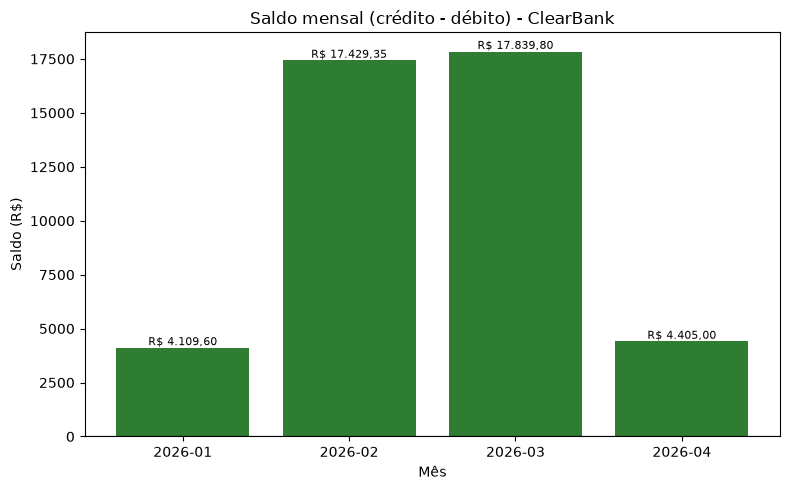

Gráfico salvo em 'grafico.png'.


In [22]:
try:
    import matplotlib.pyplot as plt

    meses = sorted(relatorio["resumo_mensal"].keys())
    saldos = [relatorio["resumo_mensal"][mes]["saldo"] for mes in meses]
    cores = ["#2e7d32" if saldo >= 0 else "#c62828" for saldo in saldos]

    plt.figure(figsize=(8, 5))
    barras = plt.bar(meses, saldos, color=cores)
    plt.title("Saldo mensal (crédito - débito) - ClearBank")
    plt.xlabel("Mês")
    plt.ylabel("Saldo (R$)")
    plt.axhline(0, color="black", linewidth=0.8)

    for barra, saldo in zip(barras, saldos):
        plt.text(
            barra.get_x() + barra.get_width() / 2,
            saldo,
            formatar_moeda(saldo),
            ha="center",
            va="bottom" if saldo >= 0 else "top",
            fontsize=8,
        )

    plt.tight_layout()
    plt.savefig("grafico.png", dpi=150)
    plt.show()
    print("Gráfico salvo em 'grafico.png'.")

except ImportError:
    print("matplotlib não está instalado neste ambiente, pulando gráfico opcional.")
